# SP Model — Scenario Creation Visualisation

This notebook visualises the two-step process used by `SP_policy_14.py` and `Two_stage_policy_14.py` to build the scenario tree at every decision step:

1. **Clustering chart** — draws 1 000 Monte Carlo samples from the price/occupancy process, runs k-means (k=10), and plots how raw samples are partitioned into scenario branches.
2. **Nodes chart** — builds the full scenario tree (`horizon=2, branches=10`) and draws it as a layered directed graph, with node size proportional to scenario probability.

In [87]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
from scipy.cluster.vq import kmeans2

# Make sure the policy folder is on the path so Data.* imports work
POLICY_DIR = os.path.dirname(os.path.abspath('__file__'))
if POLICY_DIR not in sys.path:
    sys.path.insert(0, POLICY_DIR)

from Data.PriceProcessRestaurant import price_model
from Data.OccupancyProcessRestaurant import next_occupancy_levels
from Data.v2_SystemCharacteristics import get_fixed_data

print('Imports OK')

Imports OK


## 0 · Helpers — exact copies from the SP policy

In [88]:
# ---- stochastic-model wrappers ----
def sample_price(current_price, previous_price, n):
    return np.array([price_model(current_price, previous_price) for _ in range(n)])

def sample_occ(occ1, occ2, n):
    draws = [next_occupancy_levels(occ1, occ2) for _ in range(n)]
    return np.array([d[0] for d in draws]), np.array([d[1] for d in draws])

# ---- k-means clustering (identical to _cluster in the policy) ----
def cluster(features, k, seed=42):
    n = len(features)
    if n < k:
        features = np.tile(features, (int(np.ceil(k / n)), 1))[:k]
    std = features.std(axis=0); std[std == 0] = 1.0
    centers_n, labels = kmeans2(features / std, k, iter=10, minit='points', seed=seed)
    centers = centers_n * std
    counts  = np.maximum(np.bincount(labels, minlength=k).astype(float), 1.0)
    return centers, counts / counts.sum(), labels

# ---- scenario-tree builder (identical to _build_tree in the policy) ----
_SYS   = get_fixed_data()
_T_OUT = _SYS['outdoor_temperature']

def t_out(t):
    return float(_T_OUT[max(0, min(t, len(_T_OUT) - 1))])

def build_tree(state, horizon=2, branches=10, n_init=1000):
    t_now = int(state.get('current_time', 0))
    nodes = [{
        'id': 0, 'stage': 0, 'parent_id': None, 'children': [],
        'price': float(state['price_t']),
        'price_prev': float(state.get('price_previous', state['price_t'])),
        'occ1': float(state['Occ1']), 'occ2': float(state['Occ2']),
        'T_out': t_out(t_now), 'prob': 1.0,
    }]
    m_cond   = max(n_init // branches, 30)
    leaf_ids = [0]
    for stage in range(horizon):
        n_smp        = n_init if stage == 0 else m_cond
        new_leaf_ids = []
        t_slot       = t_now + stage + 1
        for pid in leaf_ids:
            par = nodes[pid]
            p_s       = sample_price(par['price'], par['price_prev'], n_smp)
            o1_s, o2_s = sample_occ(par['occ1'], par['occ2'], n_smp)
            centers, prb, _ = cluster(np.column_stack([p_s, o1_s, o2_s]), branches)
            for b in range(branches):
                cid = len(nodes)
                nodes.append({
                    'id': cid, 'stage': stage + 1, 'parent_id': pid, 'children': [],
                    'price': float(centers[b, 0]),
                    'price_prev': par['price'],
                    'occ1': float(centers[b, 1]),
                    'occ2': float(centers[b, 2]),
                    'T_out': t_out(t_slot),
                    'prob': par['prob'] * float(prb[b]),
                })
                par['children'].append(cid)
                new_leaf_ids.append(cid)
        leaf_ids = new_leaf_ids
    return nodes

print('Helpers defined.')

Helpers defined.


## 1 · Define a representative starting state

In [103]:
np.random.seed(0)

STATE = {
    'T1': 21.0, 'T2': 21.0, 'H': 45.0,
    'Occ1': 30.0, 'Occ2': 22.0,
    'price_t': 5.0, 'price_previous': 4.5,
    'vent_counter': 0,
    'low_override_r1': 0, 'low_override_r2': 0,
    'current_time': 2,
}

HORIZON  = 2    # stages used by SP_policy_14
BRANCHES = 4   # k-means clusters per stage
N_INIT   = 1000 # Monte Carlo draws at stage 0

# ── Font-size multiplier ───────────────────────────────────────────────────────
# Increase FONT_SCALE to make all text larger; 1.0 = default sizes.
FONT_SCALE = 1.7

print(f"State at t={STATE['current_time']}: price={STATE['price_t']}, "
      f"occ1={STATE['Occ1']}, occ2={STATE['Occ2']}")
print(f"FONT_SCALE = {FONT_SCALE}")

State at t=2: price=5.0, occ1=30.0, occ2=22.0
FONT_SCALE = 1.7


---
## Chart 1 · Clustering

1 000 Monte Carlo draws of `(price_{t+1}, occ1_{t+1}, occ2_{t+1})` are drawn from the generative models, then grouped into **10 clusters** by k-means.  
The three 2-D projections show how the raw cloud collapses to 10 representative scenario branches.

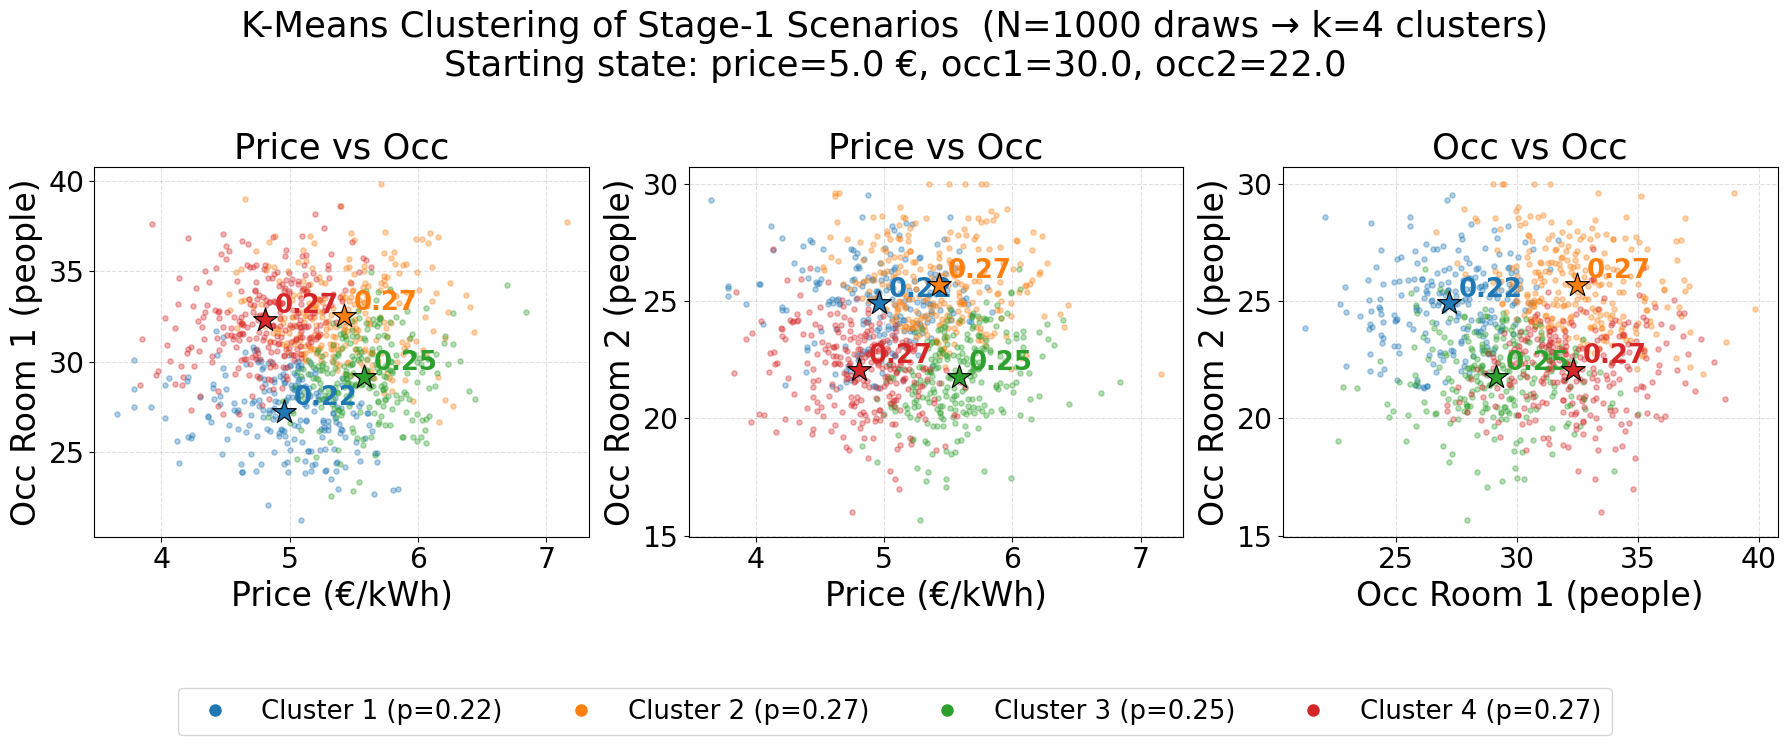

Cluster centres (price, occ1, occ2) and probabilities:
  Cluster 1: price=4.96, occ1=27.2, occ2=24.9, prob=0.219
  Cluster 2: price=5.43, occ1=32.5, occ2=25.7, prob=0.265
  Cluster 3: price=5.58, occ1=29.1, occ2=21.7, prob=0.251
  Cluster 4: price=4.81, occ1=32.3, occ2=22.0, prob=0.265


In [104]:
np.random.seed(1)

# --- draw samples ---
p_s        = sample_price(STATE['price_t'], STATE['price_previous'], N_INIT)
o1_s, o2_s = sample_occ(STATE['Occ1'], STATE['Occ2'], N_INIT)
feats      = np.column_stack([p_s, o1_s, o2_s])

# --- cluster ---
centers, probs, labels = cluster(feats, BRANCHES)

# --- colour palette ---
cmap   = plt.get_cmap('tab10')
colors = [cmap(i) for i in range(BRANCHES)]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
pairs = [(0, 1, 'Price (€/kWh)', 'Occ Room 1 (people)'),
         (0, 2, 'Price (€/kWh)', 'Occ Room 2 (people)'),
         (1, 2, 'Occ Room 1 (people)', 'Occ Room 2 (people)')]

for ax, (xi, yi, xl, yl) in zip(axes, pairs):
    for k in range(BRANCHES):
        mask = labels == k
        ax.scatter(feats[mask, xi], feats[mask, yi],
                   s=14, alpha=0.35, color=colors[k], zorder=1)
    for k in range(BRANCHES):
        ax.scatter(centers[k, xi], centers[k, yi],
                   s=320, marker='*', color=colors[k],
                   edgecolors='k', linewidths=0.8, zorder=3)
        ax.annotate(f'{probs[k]:.2f}',
                    (centers[k, xi], centers[k, yi]),
                    textcoords='offset points', xytext=(7, 5),
                    fontsize=11 * FONT_SCALE, color=colors[k], fontweight='bold')
    ax.set_xlabel(xl, fontsize=14 * FONT_SCALE)
    ax.set_ylabel(yl, fontsize=14 * FONT_SCALE)
    ax.set_title(f'{xl.split(" ")[0]} vs {yl.split(" ")[0]}', fontsize=15 * FONT_SCALE)
    ax.tick_params(axis='both', labelsize=12 * FONT_SCALE)
    ax.grid(True, linestyle='--', alpha=0.4)

handles = [mlines.Line2D([], [], marker='o', linestyle='None',
                          color=colors[k], markersize=8,
                          label=f'Cluster {k+1} (p={probs[k]:.2f})')
           for k in range(BRANCHES)]
fig.legend(handles=handles, loc='lower center', ncol=5,
           fontsize=11 * FONT_SCALE, bbox_to_anchor=(0.5, -0.20))

fig.suptitle(
    f'K-Means Clustering of Stage-1 Scenarios  '
    f'(N={N_INIT} draws → k={BRANCHES} clusters)\n'
    f'Starting state: price={STATE["price_t"]} €, '
    f'occ1={STATE["Occ1"]}, occ2={STATE["Occ2"]}',
    fontsize=15 * FONT_SCALE, y=1.03
)
plt.tight_layout()
plt.savefig('output/scenario_clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print('Cluster centres (price, occ1, occ2) and probabilities:')
for k in range(BRANCHES):
    print(f'  Cluster {k+1}: price={centers[k,0]:.2f}, '
          f'occ1={centers[k,1]:.1f}, occ2={centers[k,2]:.1f}, '
          f'prob={probs[k]:.3f}')

### Cluster probability bar chart

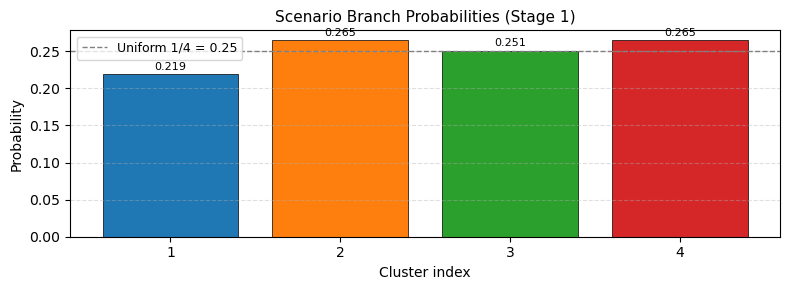

In [105]:
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.bar(range(1, BRANCHES + 1), probs,
              color=colors, edgecolor='k', linewidth=0.5)
ax.axhline(1 / BRANCHES, color='grey', linestyle='--',
           linewidth=1, label=f'Uniform 1/{BRANCHES} = {1/BRANCHES:.2f}')
for bar, p in zip(bars, probs):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
            f'{p:.3f}', ha='center', va='bottom', fontsize=8)
ax.set_xlabel('Cluster index', fontsize=10)
ax.set_ylabel('Probability', fontsize=10)
ax.set_title('Scenario Branch Probabilities (Stage 1)', fontsize=11)
ax.set_xticks(range(1, BRANCHES + 1))
ax.legend(fontsize=9)
ax.grid(True, axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('output/scenario_probs.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Chart 2 · Scenario Tree Nodes

Built with **4 branches** per stage (instead of 10) for a legible diagram:
- **Stage 0** — root, current observed state, π = 1.00
- **Stage 1** — 4 children, obtained by k-means of 1 000 Monte Carlo draws
- **Stage 2** — 4 children per Stage-1 node (100 draws each) → **21 nodes total**

Node **colour** encodes the stage; node **size** is proportional to marginal probability (within stage).  
Edges are cubic Bézier curves; **width** ∝ conditional probability.  
Conditional probabilities are annotated on Stage 0 → 1 edges.

In [106]:
BRANCHES_VIZ = 4   # reduced for a clearer visualisation (policy uses 10)

np.random.seed(2)
nodes_viz = build_tree(STATE, horizon=HORIZON, branches=BRANCHES_VIZ, n_init=N_INIT)

n_by_stage = {s: sum(1 for nd in nodes_viz if nd['stage'] == s)
              for s in range(HORIZON + 1)}
print(f'Tree built with {BRANCHES_VIZ} branches:')
for s, n in n_by_stage.items():
    print(f'  Stage {s}: {n} node(s)')
print(f'Leaf probability mass: '
      f'{sum(nd["prob"] for nd in nodes_viz if nd["stage"]==HORIZON):.4f}')

Tree built with 4 branches:
  Stage 0: 1 node(s)
  Stage 1: 4 node(s)
  Stage 2: 16 node(s)
Leaf probability mass: 1.0000


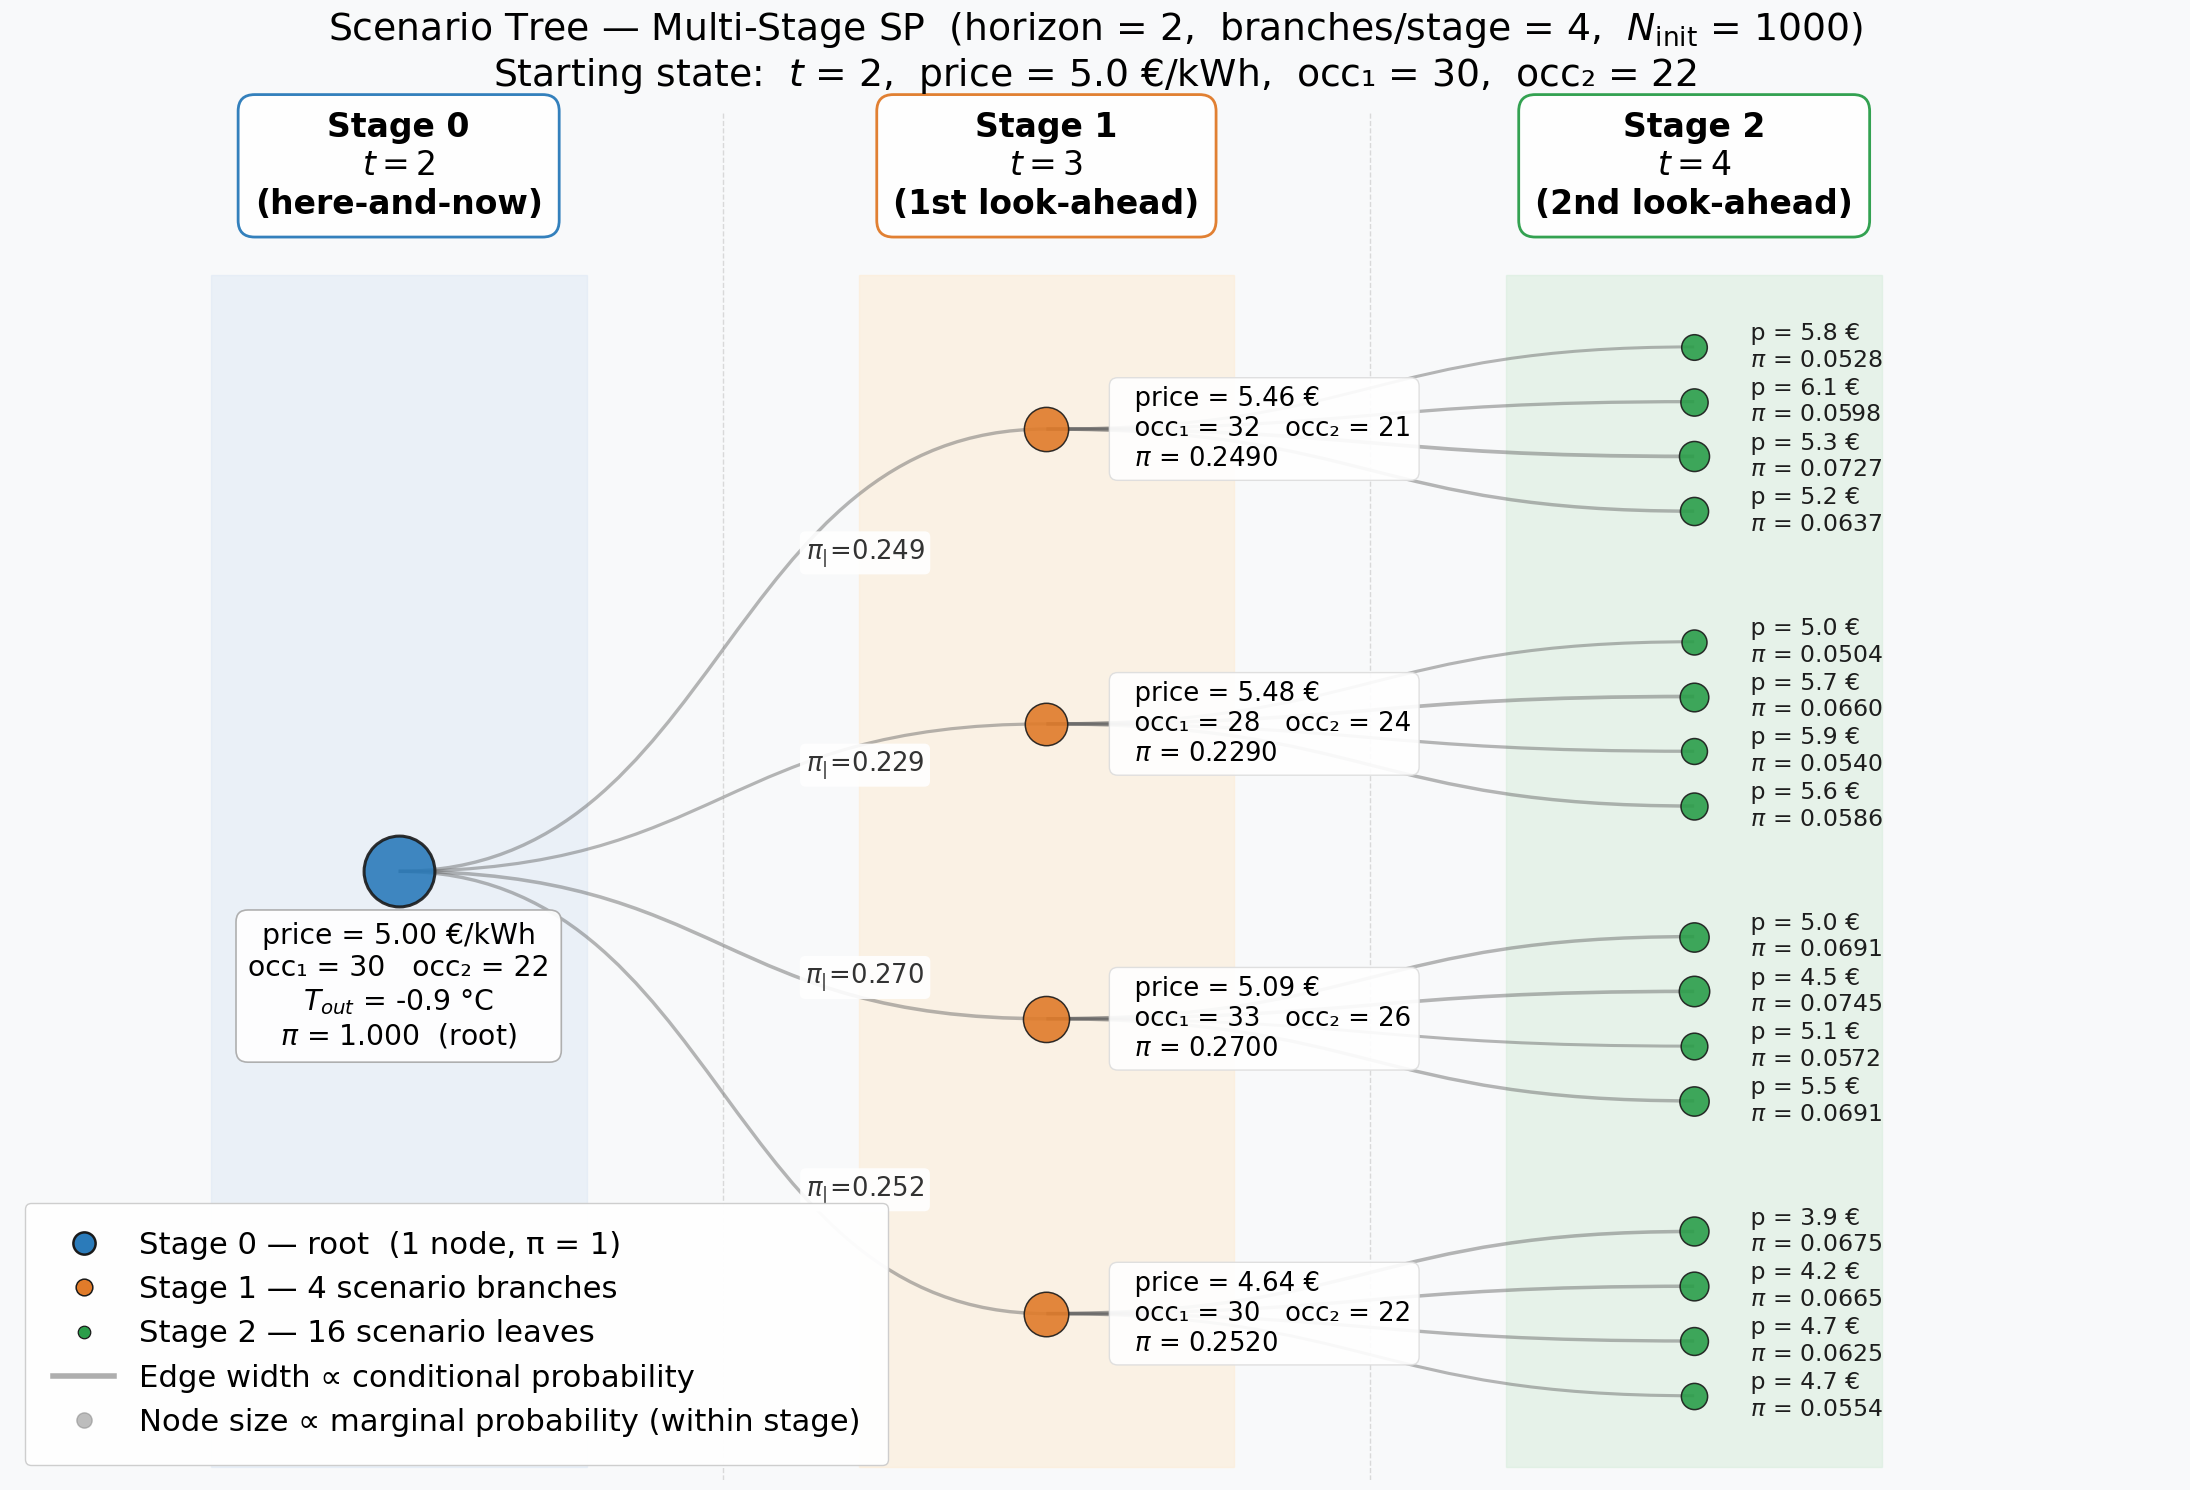

In [107]:
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np

# ── Node-map and sorted stage lists ────────────────────────────────────────────
nmap_viz     = {nd['id']: nd for nd in nodes_viz}
stage1_nodes = sorted([nd for nd in nodes_viz if nd['stage'] == 1], key=lambda x: x['id'])

# ── Horizontal stage positions: 0 → 2 → 4  (Stage-1 lands at the figure centre)
STAGE_X = {0: 0.0, 1: 2.0, 2: 4.0}

# ── Vertical layout parameters ─────────────────────────────────────────────────
GROUP_GAP = 3.5
CHILD_GAP = 0.65

# ── Node positions ─────────────────────────────────────────────────────────────
pos = {0: (STAGE_X[0], 0.0)}

n1     = len(stage1_nodes)
y1_arr = np.linspace(-(n1 - 1) / 2 * GROUP_GAP, (n1 - 1) / 2 * GROUP_GAP, n1)
for nd, y in zip(stage1_nodes, y1_arr):
    pos[nd['id']] = (STAGE_X[1], float(y))

for parent in stage1_nodes:
    children = sorted([nmap_viz[cid] for cid in parent['children']], key=lambda x: x['id'])
    n2    = len(children)
    par_y = pos[parent['id']][1]
    y2_arr = np.linspace(par_y - (n2 - 1) / 2 * CHILD_GAP,
                          par_y + (n2 - 1) / 2 * CHILD_GAP, n2)
    for child, y in zip(children, y2_arr):
        pos[child['id']] = (STAGE_X[2], float(y))

# ── Stage visual properties ────────────────────────────────────────────────────
STAGE_COLOR = {0: '#2b7bba', 1: '#e07b2a', 2: '#2b9e4a'}
BG_COLOR    = {0: '#dde8f5', 1: '#fdebd0', 2: '#d5edda'}
BASE_SIZE   = {0: 2600,      1: 1100,      2: 480}
MIN_SIZE    = {0: 2600,      1: 400,       2: 110}

max_prob_s = {s: max(nd['prob'] for nd in nodes_viz if nd['stage'] == s)
              for s in range(HORIZON + 1)}

def node_size(nd):
    s = nd['stage']
    return max(MIN_SIZE[s], BASE_SIZE[s] * nd['prob'] / max_prob_s[s])

# ── Cubic Bézier edge helper ────────────────────────────────────────────────────
def bezier_edge(ax, x0, y0, x1, y1, color, lw, alpha):
    dx = (x1 - x0) * 0.50
    verts = [(x0, y0), (x0 + dx, y0), (x1 - dx, y1), (x1, y1)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4]
    ax.add_patch(PathPatch(Path(verts, codes),
                           facecolor='none', edgecolor=color,
                           lw=lw, alpha=alpha, zorder=1))

# ── Axis limits ────────────────────────────────────────────────────────────────
all_y = [y for _, y in pos.values()]
y_lo, y_hi = min(all_y), max(all_y)
X_MIN, X_MAX = -1.2, 5.5

fig, ax = plt.subplots(figsize=(22, 15))
fig.patch.set_facecolor('#f8f9fa')
ax.set_facecolor('#f8f9fa')
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(y_lo - 1.0, y_hi + 2.8)
ax.axis('off')

# ── Soft stage-column backgrounds ─────────────────────────────────────────────
BOX_HALF_W = 0.58
for stage, xc in STAGE_X.items():
    rect = plt.Rectangle((xc - BOX_HALF_W, y_lo - 0.85),
                          BOX_HALF_W * 2, y_hi - y_lo + 1.70,
                          color=BG_COLOR[stage], alpha=0.50, zorder=0)
    ax.add_patch(rect)

# ── Stage header boxes ─────────────────────────────────────────────────────────
header_txt = {
    0: f'Stage 0\n$t = {STATE["current_time"]}$\n(here-and-now)',
    1: f'Stage 1\n$t = {STATE["current_time"]+1}$\n(1st look-ahead)',
    2: f'Stage 2\n$t = {STATE["current_time"]+2}$\n(2nd look-ahead)',
}
for stage, xc in STAGE_X.items():
    ax.text(xc, y_hi + 1.50, header_txt[stage],
            fontsize=14 * FONT_SCALE, ha='center', va='bottom',
            fontweight='bold', multialignment='center',
            bbox=dict(boxstyle='round,pad=0.50', fc='white',
                      ec=STAGE_COLOR[stage], lw=2.0, alpha=0.96))

# ── Dashed vertical stage separators ──────────────────────────────────────────
for xsep in [1.0, 3.0]:
    ax.axvline(xsep, color='#cccccc', linestyle='--', lw=1.0, alpha=0.7, zorder=0)

# ── Edges ─────────────────────────────────────────────────────────────────────
for nd in nodes_viz:
    if nd['parent_id'] is None:
        continue
    px, py    = pos[nd['parent_id']]
    cx, cy    = pos[nd['id']]
    par_prob  = nmap_viz[nd['parent_id']]['prob']
    cond_prob = nd['prob'] / par_prob if par_prob > 0 else 0
    lw        = 0.8 + cond_prob * 6.5
    bezier_edge(ax, px, py, cx, cy, '#606060', lw, alpha=0.45)

    if nd['stage'] == 1:
        mx = px * 0.28 + cx * 0.72
        my = py * 0.28 + cy * 0.72
        ax.text(mx, my, f'$\\pi_{{|}}\\!=\\!{cond_prob:.3f}$',
                fontsize=11 * FONT_SCALE, ha='center', va='center', color='#333333',
                bbox=dict(boxstyle='round,pad=0.22', fc='white',
                          ec='none', alpha=0.90))

# ── Nodes ─────────────────────────────────────────────────────────────────────
for nd in nodes_viz:
    x, y = pos[nd['id']]
    ax.scatter(x, y, s=node_size(nd),
               color=STAGE_COLOR[nd['stage']],
               edgecolors='#1a1a1a',
               linewidths=2.2 if nd['stage'] == 0 else 1.1,
               zorder=3, alpha=0.90)

# ── Node labels ───────────────────────────────────────────────────────────────
for nd in nodes_viz:
    x, y  = pos[nd['id']]
    stage = nd['stage']

    if stage == 0:
        txt = (f"price = {nd['price']:.2f} €/kWh\n"
               f"occ₁ = {nd['occ1']:.0f}   occ₂ = {nd['occ2']:.0f}\n"
               f"$T_{{out}}$ = {nd['T_out']:.1f} °C\n"
               f"$\\pi$ = 1.000  (root)")
        ax.text(x, y - 0.60, txt,
                fontsize=12 * FONT_SCALE, ha='center', va='top', multialignment='center',
                bbox=dict(boxstyle='round,pad=0.42', fc='white',
                          ec='#aaaaaa', lw=1.2, alpha=0.93))

    elif stage == 1:
        txt = (f"  price = {nd['price']:.2f} €\n"
               f"  occ₁ = {nd['occ1']:.0f}   occ₂ = {nd['occ2']:.0f}\n"
               f"  $\\pi$ = {nd['prob']:.4f}")
        ax.text(x + 0.22, y, txt,
                fontsize=11 * FONT_SCALE, ha='left', va='center', multialignment='left',
                bbox=dict(boxstyle='round,pad=0.32', fc='white',
                          ec='#dddddd', lw=1.0, alpha=0.92))

    else:
        txt = f" p = {nd['price']:.1f} €\n $\\pi$ = {nd['prob']:.4f}"
        ax.text(x + 0.15, y, txt,
                fontsize=10 * FONT_SCALE, ha='left', va='center',
                multialignment='left', color='#1e1e1e')

# ── Legend ────────────────────────────────────────────────────────────────────
legend_elems = [
    Line2D([0],[0], marker='o', linestyle='None', markersize=16,
           color=STAGE_COLOR[0], markeredgecolor='#1a1a1a', markeredgewidth=1.8,
           label='Stage 0 — root  (1 node, π = 1)'),
    Line2D([0],[0], marker='o', linestyle='None', markersize=12,
           color=STAGE_COLOR[1], markeredgecolor='#1a1a1a', markeredgewidth=1.1,
           label=f'Stage 1 — {BRANCHES_VIZ} scenario branches'),
    Line2D([0],[0], marker='o', linestyle='None', markersize=9,
           color=STAGE_COLOR[2], markeredgecolor='#1a1a1a', markeredgewidth=0.9,
           label=f'Stage 2 — {BRANCHES_VIZ**2} scenario leaves'),
    Line2D([0],[0], color='#606060', linewidth=4, alpha=0.5,
           label='Edge width ∝ conditional probability'),
    Line2D([0],[0], marker='o', linestyle='None', markersize=11,
           color='#888888', alpha=0.55,
           label='Node size ∝ marginal probability (within stage)'),
]
ax.legend(handles=legend_elems, loc='lower left', fontsize=13 * FONT_SCALE,
          framealpha=0.96, edgecolor='#cccccc', borderpad=0.9)

# ── Title ─────────────────────────────────────────────────────────────────────
ax.set_title(
    f'Scenario Tree — Multi-Stage SP  '
    f'(horizon = {HORIZON},  branches/stage = {BRANCHES_VIZ},  '
    f'$N_{{\\mathrm{{init}}}}$ = {N_INIT})\n'
    f'Starting state:  $t$ = {STATE["current_time"]},  '
    f'price = {STATE["price_t"]} €/kWh,  '
    f'occ₁ = {STATE["Occ1"]:.0f},  occ₂ = {STATE["Occ2"]:.0f}',
    fontsize=16 * FONT_SCALE, pad=18
)

plt.tight_layout()
plt.savefig('output/scenario_tree.png', dpi=180, bbox_inches='tight',
            facecolor='#f8f9fa')
plt.show()

### Node summary table

In [108]:
import pandas as pd

df_viz = pd.DataFrame([
    {'stage': nd['stage'], 'id': nd['id'], 'parent_id': nd['parent_id'],
     'price': round(nd['price'], 3),
     'occ1': round(nd['occ1'], 1), 'occ2': round(nd['occ2'], 1),
     'T_out': round(nd['T_out'], 2),
     'prob': round(nd['prob'], 5)}
    for nd in nodes_viz
])

print(f'Total nodes: {len(df_viz)}')
print()
print('── Stage 0 (root) ──')
print(df_viz[df_viz.stage == 0].to_string(index=False))
print()
print('── Stage 1 ──')
print(df_viz[df_viz.stage == 1].to_string(index=False))
print()
print('── Stage 2 ──')
print(df_viz[df_viz.stage == 2].to_string(index=False))
print()
print('Probability mass check (all leaves sum to):',
      df_viz[df_viz.stage == HORIZON]['prob'].sum().round(4))

Total nodes: 21

── Stage 0 (root) ──
 stage  id  parent_id  price  occ1  occ2  T_out  prob
     0   0        NaN    5.0  30.0  22.0  -0.93   1.0

── Stage 1 ──
 stage  id  parent_id  price  occ1  occ2  T_out  prob
     1   1        0.0  4.637  29.6  22.4   0.93 0.252
     1   2        0.0  5.087  32.9  25.5   0.93 0.270
     1   3        0.0  5.483  27.6  24.3   0.93 0.229
     1   4        0.0  5.456  32.1  21.2   0.93 0.249

── Stage 2 ──
 stage  id  parent_id  price  occ1  occ2  T_out    prob
     2   5        1.0  4.738  27.3  23.0   2.43 0.05544
     2   6        1.0  4.696  32.9  24.9   2.43 0.06250
     2   7        1.0  4.155  30.9  20.9   2.43 0.06653
     2   8        1.0  3.862  28.8  25.2   2.43 0.06754
     2   9        2.0  5.466  32.6  27.7   2.43 0.06912
     2  10        2.0  5.145  34.9  23.9   2.43 0.05724
     2  11        2.0  4.470  33.9  27.1   2.43 0.07452
     2  12        2.0  5.034  29.9  24.3   2.43 0.06912
     2  13        3.0  5.637  31.4  26.9   2.43 0.

---
## Bonus · Effect of k on clustering quality

How does the number of clusters affect the within-cluster sum of squared distances (inertia)?  Helps choose `BRANCHES`.

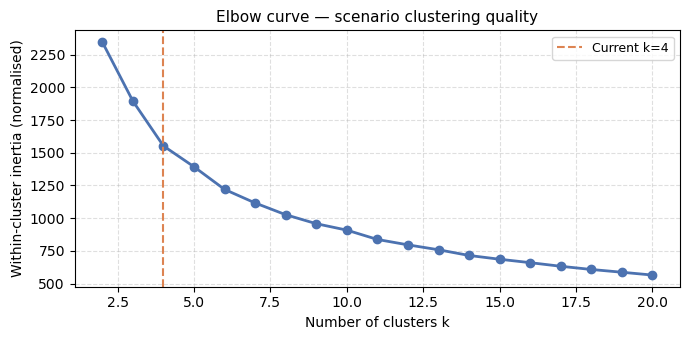

In [109]:
np.random.seed(3)
p_s2       = sample_price(STATE['price_t'], STATE['price_previous'], N_INIT)
o1_s2, o2_s2 = sample_occ(STATE['Occ1'], STATE['Occ2'], N_INIT)
feats2     = np.column_stack([p_s2, o1_s2, o2_s2])

std2 = feats2.std(axis=0); std2[std2 == 0] = 1.0
feats2_n = feats2 / std2

k_range  = range(2, 21)
inertias = []
for k in k_range:
    centers_n, labels = kmeans2(feats2_n, k, iter=20, minit='points', seed=42)
    inertia = sum(
        np.sum((feats2_n[labels == i] - centers_n[i]) ** 2)
        for i in range(k)
    )
    inertias.append(inertia)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(list(k_range), inertias, 'o-', color='#4c72b0', linewidth=2, markersize=6)
ax.axvline(BRANCHES, color='#dd8452', linestyle='--', linewidth=1.5,
           label=f'Current k={BRANCHES}')
ax.set_xlabel('Number of clusters k', fontsize=10)
ax.set_ylabel('Within-cluster inertia (normalised)', fontsize=10)
ax.set_title('Elbow curve — scenario clustering quality', fontsize=11)
ax.legend(fontsize=9)
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('output/elbow_curve.png', dpi=150, bbox_inches='tight')
plt.show()